In [ ]:
import kagglehub

path = kagglehub.dataset_download("mashlyn/online-retail-ii-uci")

print("Dataset downloaded at:", path)

Using Colab cache for faster access to the 'online-retail-ii-uci' dataset.
Dataset downloaded at: /kaggle/input/online-retail-ii-uci


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
import os

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

In [ ]:
df=pd.read_csv("/kaggle/input/online-retail-ii-uci/online_retail_II.csv")

In [ ]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [ ]:
df.shape

(1067371, 8)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


In [ ]:
df.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [ ]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


In [ ]:
df.dropna(subset=['Customer ID'], inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df = df[~df['Invoice'].astype(str).str.startswith('C')]

In [ ]:
df = df[
    (df['Quantity'] > 0) &
    (df['Price'] > 0)
]

In [ ]:
df.shape

(779425, 8)

In [ ]:
df['Revenue'] = df['Quantity'] * df['Price']
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [ ]:
df['Monetary'] = df['Quantity'] * df['Price']

In [ ]:
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

In [ ]:
rfm = df.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'Invoice': 'nunique',
    'Monetary': 'sum'
})

In [ ]:
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'Invoice': 'Frequency'
}, inplace=True)

In [ ]:
rfm.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346.0,326,12,77556.46
12347.0,2,8,4921.53
12348.0,75,5,2019.40
12349.0,19,4,4428.69
12350.0,310,1,334.40


In [ ]:
X = rfm[['Recency', 'Frequency', 'Monetary']]

In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [ ]:
wcss = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    wcss.append(model.inertia_)

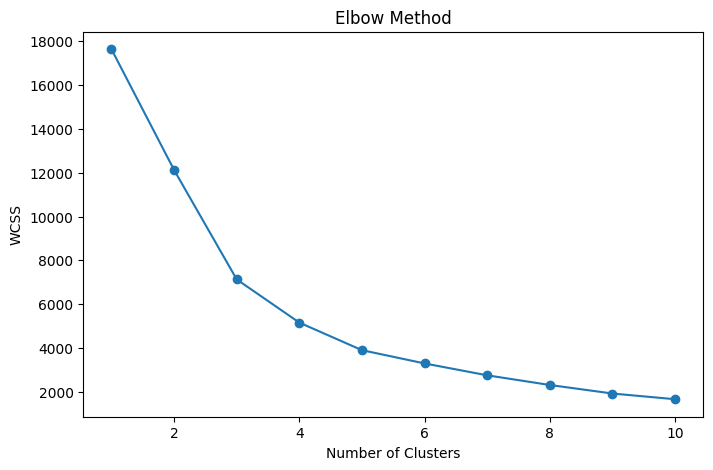

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(range(1,11), wcss, marker='o')

plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')

plt.show()

In [ ]:
scores = []

for k in range(2,11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    scores.append(silhouette_score(X_scaled, labels))

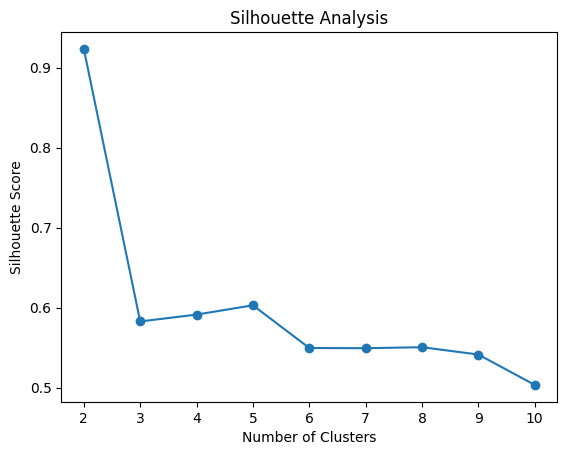

In [ ]:
plt.plot(range(2,11), scores, marker='o')

plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis')

plt.show()

In [ ]:
for k in [2, 3, 4, 5]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    print(f"\nK = {k}")
    print(pd.Series(labels).value_counts().sort_index())


K = 2
0      18
1    5860
Name: count, dtype: int64

K = 3
0    3847
1    2009
2      22
Name: count, dtype: int64

K = 4
0    3838
1    1998
2       4
3      38
Name: count, dtype: int64

K = 5
0    3575
1    1922
2       4
3      24
4     353
Name: count, dtype: int64


In [ ]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

In [ ]:
rfm.groupby('KMeans_Cluster')[
    ['Recency', 'Frequency', 'Monetary']
].mean()

,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,66.296335,7.640239,3136.130157
1,461.861125,2.205077,747.333351
2,23.090909,143.045455,173123.584091


In [ ]:
rfm['KMeans_Cluster'].value_counts().sort_index()

,count
KMeans_Cluster,
0,3847
1,2009
2,22


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

In [ ]:
print("Explained variance ratio:", pca.explained_variance_ratio_)

print("Total variance explained:",
      pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.57629786 0.30464034]
Total variance explained: 0.8809382002936084


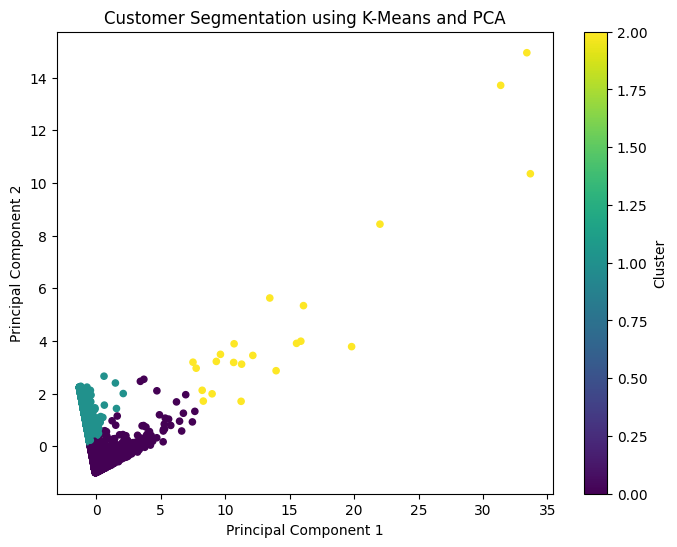

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=rfm['KMeans_Cluster'],
    cmap='viridis',
    s=20
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Customer Segmentation using K-Means and PCA')

plt.colorbar(label='Cluster')
plt.show()

In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

rfm['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

In [ ]:
rfm['DBSCAN_Cluster'].value_counts().sort_index()

,count
DBSCAN_Cluster,
-1,63
0,5815


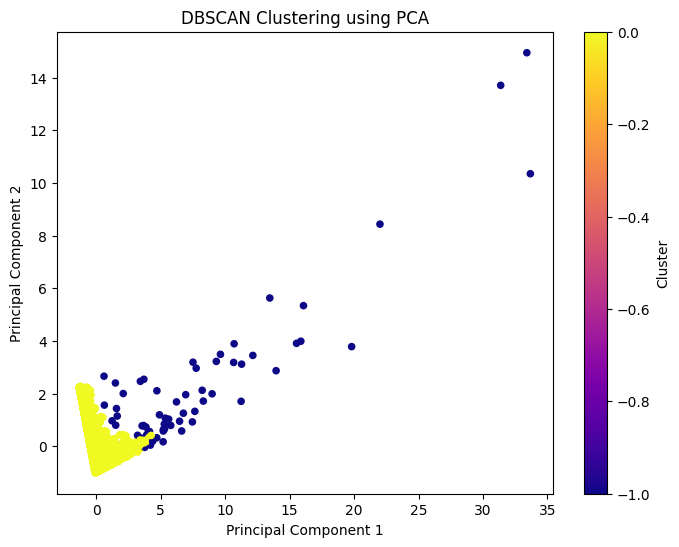

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=rfm['DBSCAN_Cluster'],
    cmap='plasma',
    s=20
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('DBSCAN Clustering using PCA')

plt.colorbar(label='Cluster')
plt.show()

In [ ]:
rfm.groupby('DBSCAN_Cluster')[
    ['Recency', 'Frequency', 'Monetary']
].mean()

,Recency,Frequency,Monetary
DBSCAN_Cluster,,,
-1,81.190476,83.730159,86437.550683
0,202.633534,5.450387,2051.459772


In [ ]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init='pca',
    learning_rate='auto'
)

X_tsne = tsne.fit_transform(X_scaled)

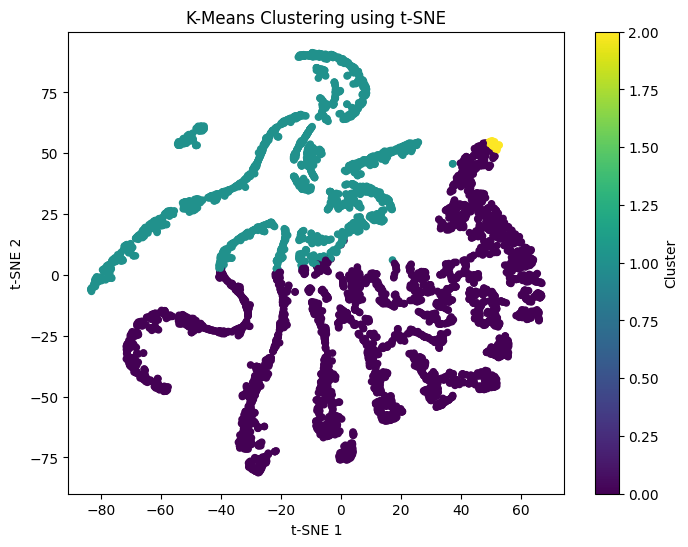

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=rfm['KMeans_Cluster'],
    cmap='viridis',
    s=20
)

plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('K-Means Clustering using t-SNE')

plt.colorbar(label='Cluster')
plt.show()

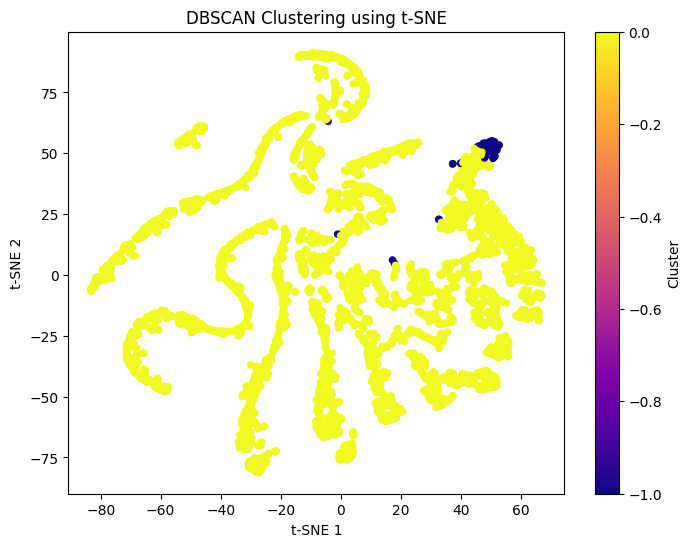

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=rfm['DBSCAN_Cluster'],
    cmap='plasma',
    s=20
)

plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('DBSCAN Clustering using t-SNE')

plt.colorbar(label='Cluster')
plt.show()

In [ ]:
print("K-Means Cluster Distribution:")
print(rfm['KMeans_Cluster'].value_counts().sort_index())

print("\nDBSCAN Cluster Distribution:")
print(rfm['DBSCAN_Cluster'].value_counts().sort_index())

K-Means Cluster Distribution:
KMeans_Cluster
0    3847
1    2009
2      22
Name: count, dtype: int64

DBSCAN Cluster Distribution:
DBSCAN_Cluster
-1      63
 0    5815
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# K-Means evaluation
kmeans_labels = rfm['KMeans_Cluster']

print("K-Means Silhouette:",
      silhouette_score(X_scaled, kmeans_labels))

print("K-Means Davies-Bouldin:",
      davies_bouldin_score(X_scaled, kmeans_labels))

print("K-Means Calinski-Harabasz:",
      calinski_harabasz_score(X_scaled, kmeans_labels))

K-Means Silhouette: 0.5827464842414258
K-Means Davies-Bouldin: 0.6681548799891509
K-Means Calinski-Harabasz: 4326.7212017300235


In [ ]:
print(rfm['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN_Cluster
-1      63
 0    5815
Name: count, dtype: int64


In [ ]:
for e in [0.2, 0.3, 0.4, 0.5, 0.7, 1.0]:
    dbscan = DBSCAN(eps=e, min_samples=5)
    labels = dbscan.fit_predict(X_scaled)

    print("eps:", e)
    print(pd.Series(labels).value_counts().sort_index())
    print()

eps: 0.2
-1     194
 0    5684
Name: count, dtype: int64

eps: 0.3
-1     122
 0    5750
 1       6
Name: count, dtype: int64

eps: 0.4
-1      74
 0    5804
Name: count, dtype: int64

eps: 0.5
-1      63
 0    5815
Name: count, dtype: int64

eps: 0.7
-1      52
 0    5821
 1       5
Name: count, dtype: int64

eps: 1.0
-1      46
 0    5832
Name: count, dtype: int64

